# 4.1.- Regresión Lineal, Logística y Softmax (Multiclase) con Keras

En este notebook veremos tres modelos fundamentales de aprendizaje supervisado, todos implementados con **Keras**:

1. **Regresión lineal:** predice valores numéricos continuos.  
2. **Regresión logística:** clasifica entre dos clases (0 o 1).  
3. **Softmax:** clasifica entre tres o más clases.

Los tres modelos comparten la misma estructura básica:

$$
\hat{y} = f(Wx + b)
$$

donde:
- $x$ = entrada,  
- $W$ = pesos,  
- $b$ = sesgo,  
- $f(\cdot)$ = función de activación (diferente en cada caso).

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import make_blobs

np.random.seed(33)
tf.random.set_seed(33)
plt.rcParams["figure.figsize"] = (12, 6)

## Regresión Lineal

La **regresión lineal** busca una función que relacione la variable de entrada $x$ con la salida $y$ mediante una combinación lineal:

$$
\hat{y} = Wx + b
$$

donde:
- $W$ es la pendiente (peso),
- $b$ es el sesgo (intersección).

El modelo se entrena minimizando el **error cuadrático medio (MSE)**:

$$
J = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$

En Keras, se implementa sin función de activación en la capa de salida (`activation=None`).

Loss ≈ 0.011
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


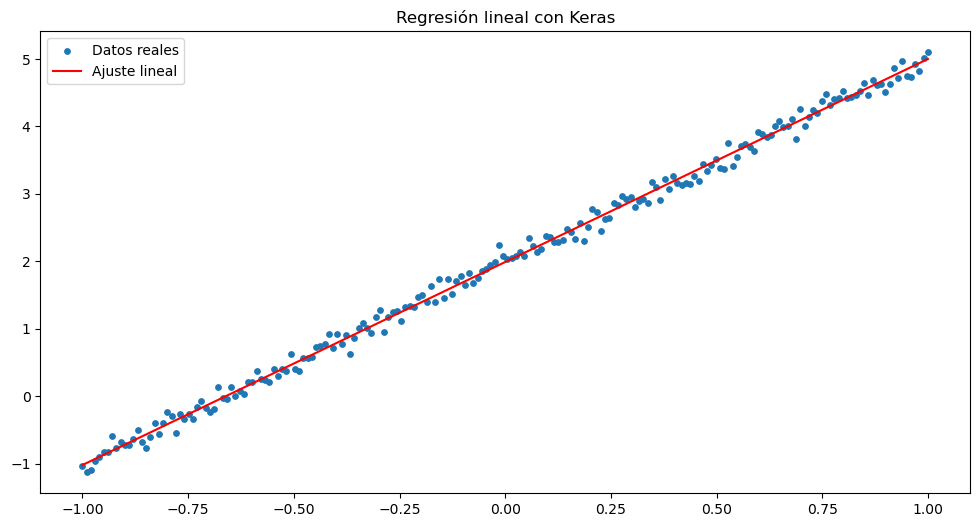

In [23]:
# Datos sintéticos: y = 3x + 2 + ruido
X, y = np.linspace(-1, 1, 200).reshape(-1, 1), 3 * np.linspace(-1, 1, 200).reshape(-1, 1) + 2 + np.random.normal(0, 0.1, (200, 1))

# Modelo lineal (sin activación)
model = keras.Sequential([
    keras.Input(shape=(1,)),
    layers.Dense(1)
])

# Entrenamiento
model.compile(optimizer='sgd', loss='mse')
model.fit(X, y, epochs=500, verbose=0)

# Evaluación
loss = model.evaluate(X, y, verbose=0)
print(f"Loss ≈ {loss:.3f}")

# Predicciones
y_pred = model.predict(X)

# Gráfico
plt.scatter(X, y, s=15, label="Datos reales")
plt.plot(X, y_pred, color='red', label="Ajuste lineal")
plt.title("Regresión lineal con Keras")
plt.legend()
plt.show()

## Regresión Logística (Clasificación Binaria)

La **regresión logística** transforma la salida lineal mediante una función sigmoide, de modo que el resultado esté entre 0 y 1:

$$
\hat{y} = \sigma(Wx + b)
$$

donde la **función sigmoide** es:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Interpretamos $\hat{y}$ como la **probabilidad** de pertenecer a la clase 1.

La **función de pérdida** usada es la **entropía cruzada binaria**:

$$
Log-Loss = -\frac{1}{n}\sum_{i=1}^{n} \left[y_i \log(\hat{y}_i) + (1-y_i)\log(1-\hat{y}_i)\right]
$$

Loss ≈ 0.147
Accuracy ≈ 0.997
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


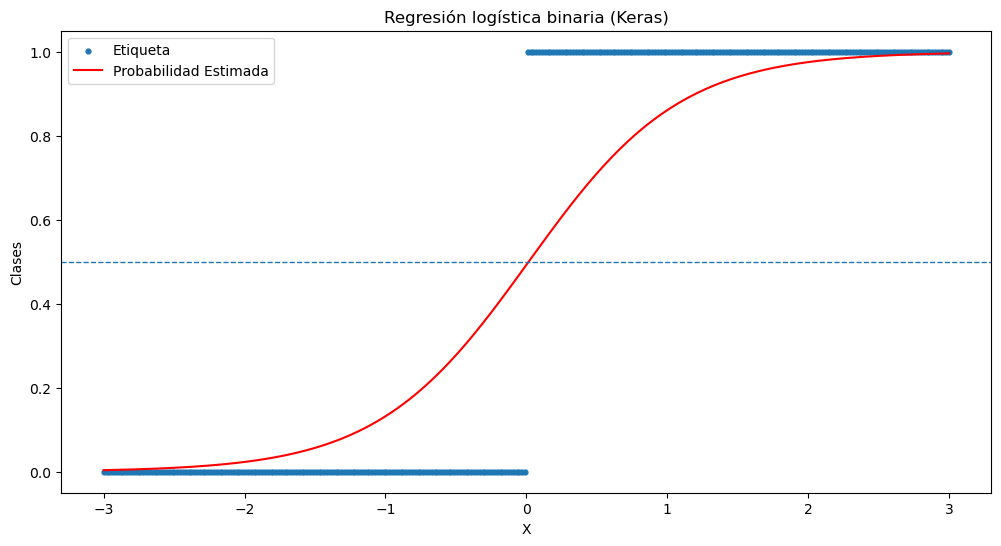

In [24]:
# Datos sintéticos: y = 1 si x > 0
X, y = np.linspace(-3, 3, 300).reshape(-1, 1), (np.linspace(-3, 3, 300) > 0).astype("float32")

# Modelo logístico (sigmoid)
model = keras.Sequential([
    keras.Input(shape=(1,)),
    layers.Dense(1, activation='sigmoid')
])

# Entrenamiento
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.fit(X, y, epochs=300, verbose=0)

# Evaluación
loss, acc = model.evaluate(X, y, verbose=0)
print(f"Loss ≈ {loss:.3f}")
print(f"Accuracy ≈ {acc:.3f}")

# Predicciones
probs = model.predict(X).reshape(-1)
preds = (probs >= 0.5).astype("float32")

# Gráfico
order = np.argsort(X[:, 0])
plt.scatter(X, y, s=12, label="Etiqueta")
plt.plot(X[order], probs[order], color="red", label="Probabilidad Estimada")
plt.axhline(0.5, ls="--", lw=1)
plt.title("Regresión logística binaria (Keras)")
plt.xlabel("X")
plt.ylabel("Clases")
plt.legend()
plt.show()

## Clasificación Multiclase con Softmax

La **regresión softmax** generaliza la regresión logística a múltiples clases.

Para $j$ clases, la salida de cada neurona $i$ se calcula como:

$$
P(y=i \mid x) = \frac{e^{z_i}}{\sum_{j=1}^{j} e^{z_j}}
$$

Esto produce una **distribución de probabilidad**, donde la suma de todas las clases es igual a 1.

La función de pérdida correspondiente es la **entropía cruzada categórica**:

$$
L = -\frac{1}{n} \sum_{i=1}^{n} \log(P(y_i \mid x_i))
$$


Loss ≈ 0.023
Accuracy ≈ 1.000
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


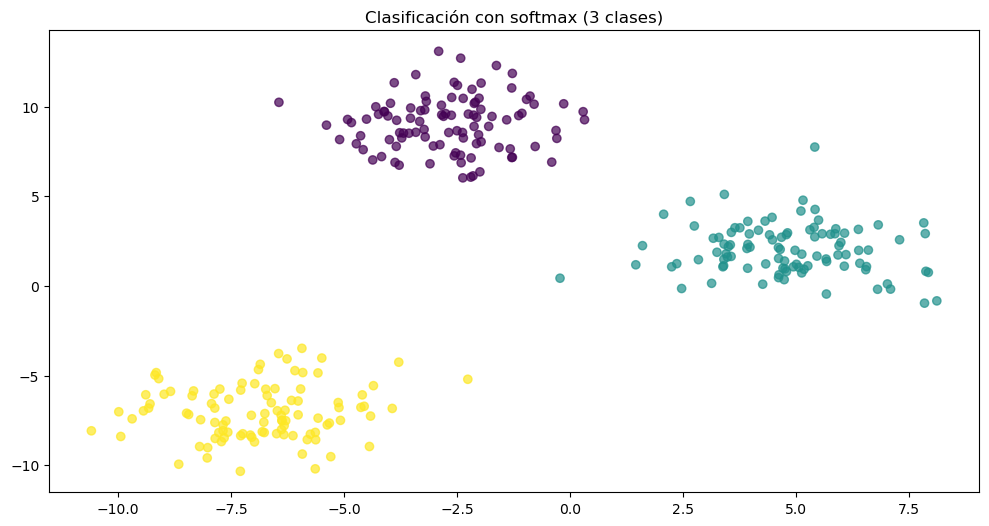

In [28]:
# Dataset sintético con 3 clases (2 características)
X, y = make_blobs(n_samples=300, centers=3, random_state=42, cluster_std=1.5)

# Modelo softmax (3 clases)
model = keras.Sequential([
    keras.Input(shape=(2,)),
    layers.Dense(3, activation='softmax')
])

# Entrenamiento
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(X, y, epochs=300, verbose=0)

# Evaluación
loss, acc = model.evaluate(X, y, verbose=0)
print(f"Loss ≈ {loss:.3f}")
print(f"Accuracy ≈ {acc:.3f}")

# Predicciones
probs = model.predict(X)
preds = np.argmax(probs, axis=1)

# Gráfico
plt.scatter(X[:, 0], X[:, 1], c=preds, cmap='viridis', alpha=0.7)
plt.title("Clasificación con softmax (3 clases)")
plt.show()

## Resumen Conceptual

| Tipo de modelo | Activación | Salida | Pérdida usada | Ejemplo de uso |
|----------------|-------------|---------|----------------|----------------|
| Regresión lineal | None | Valor real | MSE | Predicción de precios |
| Regresión logística | Sigmoid | Prob. clase 1 | Binary Crossentropy | Clasificación binaria |
| Softmax | Softmax | Prob. en varias clases | Categorical Crossentropy | Clasificación multiclase |

### Relaciones Clave

- Todos los modelos tienen la forma general $ \hat{y} = f(Wx + b) $.
- La diferencia está en la **función de activación** $f$ y en la **pérdida** usada.
- Estas tres variantes son la base de redes neuronales más complejas (como las MLP o CNN).